
First Five Records
        Date       Category  Amount
0 2026-04-13          Bills    1965
1 2026-04-03           Food    3012
2 2026-01-15     Healthcare    2953
3 2026-04-17  Entertainment    3328
4 2026-03-13           Food    3819

Total Expense
1324286

Average Expense
2648.57

Highest Expense
4995

Lowest Expense
102

Category-wise Expense
Category
Healthcare       255312
Bills            220466
Food             219112
Shopping         214726
Entertainment    208821
Transport        205849
Name: Amount, dtype: int32

Monthly Expense
Month
April       272710
February    276523
January     256192
March       219393
May         299468
Name: Amount, dtype: int32

Highest Spending Day
2026-04-09 00:00:00 ₹ 29510


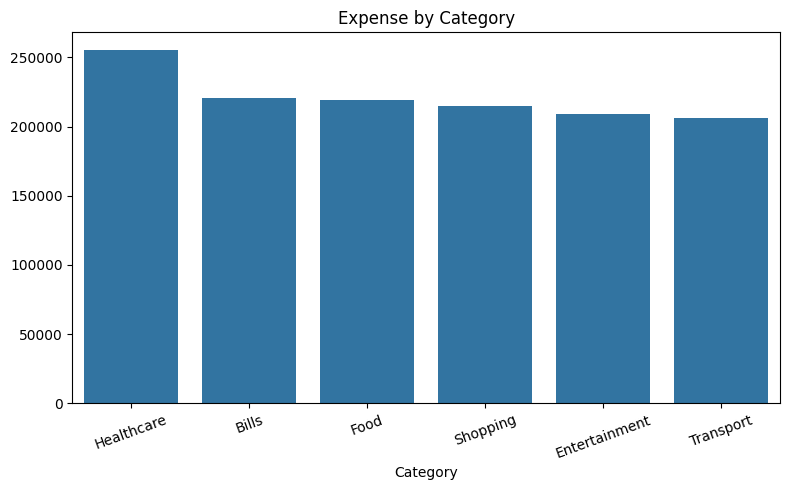

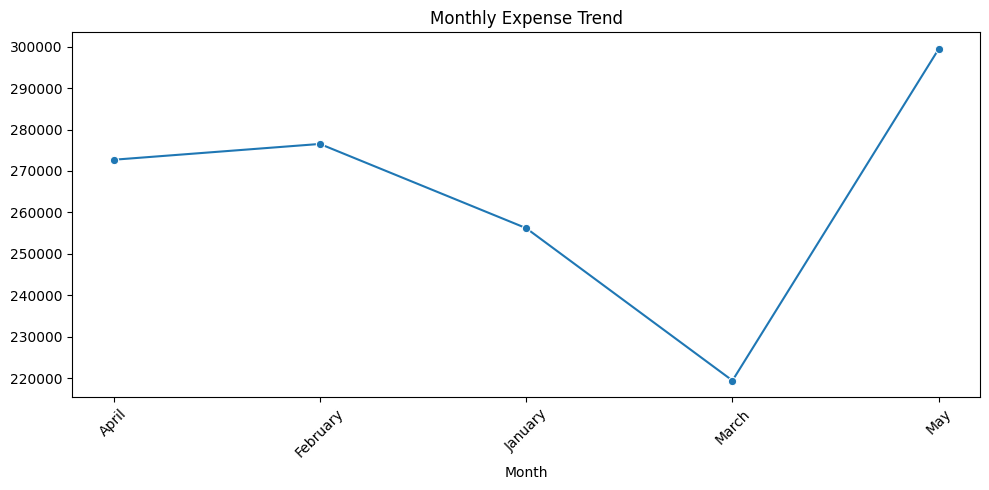

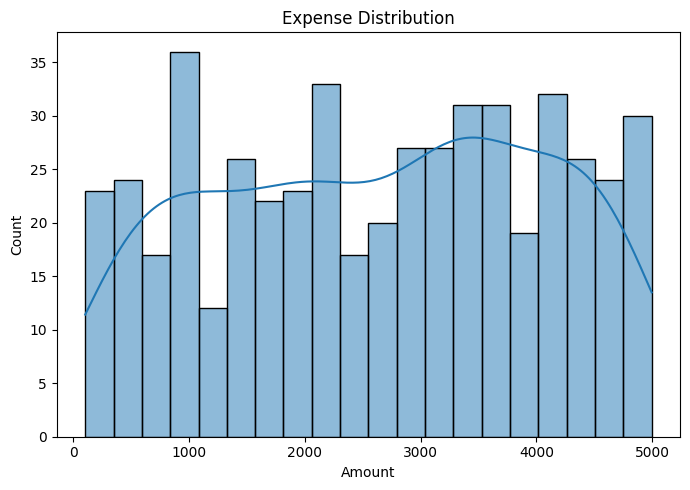

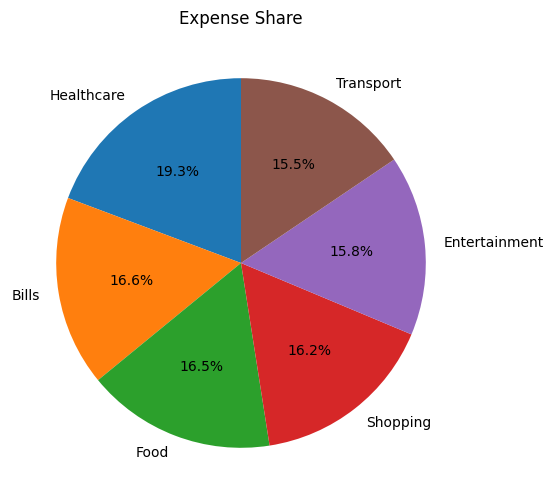

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------
# Generate Sample Expense Data
# ----------------------------
np.random.seed(42)

categories = [
    "Food",
    "Transport",
    "Shopping",
    "Entertainment",
    "Bills",
    "Healthcare"
]

dates = pd.date_range("2026-01-01", periods=150)

df = pd.DataFrame({
    "Date": np.random.choice(dates, 500),
    "Category": np.random.choice(categories, 500),
    "Amount": np.random.randint(100, 5000, 500)
})

# ----------------------------
# Data Analysis
# ----------------------------
print("\nFirst Five Records")
print(df.head())

print("\nTotal Expense")
print(df["Amount"].sum())

print("\nAverage Expense")
print(round(df["Amount"].mean(), 2))

print("\nHighest Expense")
print(df["Amount"].max())

print("\nLowest Expense")
print(df["Amount"].min())

# ----------------------------
# Category-wise Expense
# ----------------------------
category_expense = (
    df.groupby("Category")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

print("\nCategory-wise Expense")
print(category_expense)

# ----------------------------
# Monthly Expense
# ----------------------------
df["Month"] = df["Date"].dt.strftime("%B")

monthly = df.groupby("Month")["Amount"].sum()

print("\nMonthly Expense")
print(monthly)

# ----------------------------
# Highest Spending Day
# ----------------------------
daily = df.groupby("Date")["Amount"].sum()

print("\nHighest Spending Day")
print(daily.idxmax(), "₹", daily.max())

# ----------------------------
# Visualization
# ----------------------------

plt.figure(figsize=(8,5))
sns.barplot(
    x=category_expense.index,
    y=category_expense.values
)
plt.title("Expense by Category")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,5))
sns.lineplot(
    x=monthly.index,
    y=monthly.values,
    marker="o"
)
plt.title("Monthly Expense Trend")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
sns.histplot(df["Amount"], bins=20, kde=True)
plt.title("Expense Distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,6))
plt.pie(
    category_expense.values,
    labels=category_expense.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Expense Share")
plt.show()